# Deaths on the World's Eight-Thousanders

This notebook analyzes recorded deaths by cause, season, and period. Charts are saved to `outputs/figures/`, and summary tables are saved to `outputs/`.

The results describe records in the supplied source and may not represent a complete historical account.

## 1. Libraries and paths

We use pandas to work with the tabular data and Matplotlib to create charts. The notebook locates the project directory whether it is launched from the project root or from `notebooks/`.

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'deaths_on_eight-thousanders.csv').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / 'deaths_on_eight-thousanders.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs'
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 120
print(f'Dane: {DATA_PATH}')
print(f'Wyniki: {OUTPUT_DIR}')

Dane: C:\GITHUB\climbing_accidents\deaths_on_eight-thousanders.csv
Wyniki: C:\GITHUB\climbing_accidents\outputs


## 2. Load and inspect the data

We check the table dimensions, columns, and missing values. Dates are parsed carefully: invalid values become missing and are not assigned to a season or period.

In [2]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
df.columns = df.columns.str.strip()
required_columns = {'Date', 'Cause of death', 'Mountain'}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required CSV columns: {', '.join(sorted(missing_columns))}")
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
print(f'Records: {len(df):,}')
print(f'Mountains: {df["Mountain"].nunique()}')
display(df.head())
display(df.isna().sum().rename('missing values').to_frame())

Records: 1,078
Mountains: 14


,Date,Name,Nationality,Cause of death,Mountain
0,2023-07-27,Muhammad Hassan,Pakistan,Unknown,K2
1,2022-07-22,Matthew Eakin,Australia,Fall,K2
2,2022-07-22,Richard Cartier,Canada,Fall,K2
3,2022-07-21,Ali Akbar Sakhi,Afghanistan,"Unknown, suspected altitude sickness",K2
4,2021-07-25,Rick Allen,United Kingdom,Avalanche,K2


,missing values
Date,0
Name,0
Nationality,2
Cause of death,9
Mountain,0


## 3. Cause categories

Source descriptions vary in detail. We group them by keywords to make comparisons between mountains possible. This is a simplification; source descriptions in the CSV remain unchanged. Unknown and unmatched causes are labeled explicitly.

In [3]:
CAUSE_RULES = [
    ('Avalanche / serac', r'avalanche|serac'),
    ('Fall', r'fall|fell|crevasse'),
    ('Altitude illness', r'altitude|HACE|HAPE|pulmonary edema|cerebral edema'),
    ('Exposure / cold', r'exposure|frostbite|froze|hypothermia|cold'),
    ('Missing / disappeared', r'disappear|missing|lost'),
    ('Violence', r'killed by|murder|shot|taliban|attack'),
    ('Illness / medical', r'illness|heart attack|stroke|pneumonia|medical|sickness'),
    ('Exhaustion', r'exhaustion|exhausted'),
]


In [4]:
def classify_cause(value):
    text = '' if pd.isna(value) else str(value).strip()
    if not text or re.search(r'\bunknown\b|unspecified', text, re.I):
        return 'Unknown / unspecified'
    for label, pattern in CAUSE_RULES:
        if re.search(pattern, text, re.I):
            return label
    return 'Other / unclear'

df['cause_category'] = df['Cause of death'].map(classify_cause)
cause_counts = (df.dropna(subset=['Mountain']).groupby(['Mountain', 'cause_category'])
                .size().rename('deaths').reset_index())
cause_counts['is_most_common'] = cause_counts['deaths'].eq(
    cause_counts.groupby('Mountain')['deaths'].transform('max'))
cause_counts.to_csv(OUTPUT_DIR / 'deaths_by_cause_and_mountain.csv', index=False, encoding='utf-8-sig')
display(cause_counts[cause_counts['is_most_common']].sort_values('Mountain'))

,Mountain,cause_category,deaths,is_most_common
1,Annapurna I,Avalanche / serac,41,True
10,Broad Peak,Fall,14,True
16,Cho Oyu,Fall,18,True
20,Dhaulagiri I,Avalanche / serac,43,True
29,Gasherbrum I,Fall,11,True
31,Gasherbrum I,Missing / disappeared,11,True
36,Gasherbrum II,Fall,9,True
44,K2,Fall,32,True
53,Kangchenjunga,Fall,31,True
57,Lhotse,Avalanche / serac,13,True


## 4. Seasons

The eight-thousanders are in the Northern Hemisphere, so we use Northern Hemisphere seasons: winter (December-February), spring (March-May), summer (June-August), and autumn (September-November). The table includes zero counts for easier comparisons.

In [5]:
SEASON_MAP = {12: 'Winter', 1: 'Winter', 2: 'Winter', 3: 'Spring', 4: 'Spring', 5: 'Spring',
              6: 'Summer', 7: 'Summer', 8: 'Summer', 9: 'Autumn', 10: 'Autumn', 11: 'Autumn'}
SEASON_ORDER = ['Winter', 'Spring', 'Summer', 'Autumn']
df['season'] = df['Date'].dt.month.map(SEASON_MAP)
mountains = sorted(df['Mountain'].dropna().unique())
season_counts = df.dropna(subset=['Mountain', 'season']).groupby(['Mountain', 'season']).size().rename('deaths').reset_index()
season_counts = (pd.MultiIndex.from_product([mountains, SEASON_ORDER], names=['Mountain', 'season']).to_frame(index=False)
                 .merge(season_counts, how='left').fillna({'deaths': 0}))
season_counts['deaths'] = season_counts['deaths'].astype(int)
season_counts.to_csv(OUTPUT_DIR / 'deaths_by_season_and_mountain.csv', index=False, encoding='utf-8-sig')
display(season_counts.pivot(index='Mountain', columns='season', values='deaths')[SEASON_ORDER])

season,Winter,Spring,Summer,Autumn
Mountain,,,,
Annapurna I,6,27,0,41
Broad Peak,0,3,34,0
Cho Oyu,5,22,1,24
Dhaulagiri I,3,45,1,34
Gasherbrum I,0,5,28,1
Gasherbrum II,0,2,22,0
K2,6,0,90,0
Kangchenjunga,6,37,5,11
Lhotse,1,17,0,15


## 5. Periods relative to 2000

We separate years before 2000 from 2000 onwards, so records from calendar year 2000 are included in the after-2000 category.

In [6]:
df['period'] = pd.NA
valid_date = df['Date'].notna()
df.loc[valid_date & (df['Date'].dt.year < 2000), 'period'] = 'before_2000'
df.loc[valid_date & (df['Date'].dt.year >= 2000), 'period'] = 'after_2000'
PERIOD_ORDER = ['before_2000', 'after_2000']
period_counts = df.dropna(subset=['Mountain', 'period']).groupby(['Mountain', 'period']).size().rename('deaths').reset_index()
period_counts = (pd.MultiIndex.from_product([mountains, PERIOD_ORDER], names=['Mountain', 'period']).to_frame(index=False)
                 .merge(period_counts, how='left').fillna({'deaths': 0}))
period_counts['deaths'] = period_counts['deaths'].astype(int)
period_counts.to_csv(OUTPUT_DIR / 'deaths_by_period_and_mountain.csv', index=False, encoding='utf-8-sig')
display(period_counts.pivot(index='Mountain', columns='period', values='deaths')[PERIOD_ORDER])

period,before_2000,after_2000
Mountain,,
Annapurna I,56,18
Broad Peak,21,16
Cho Oyu,26,26
Dhaulagiri I,49,34
Gasherbrum I,17,17
Gasherbrum II,15,9
K2,49,47
Kangchenjunga,43,16
Lhotse,16,17


## 6. Charts

We create three charts and save them as PNG files in `outputs/figures/`. The first shows the most common cause categories, including ties; the second shows seasonal counts; the third shows counts by period. These are raw counts, with no adjustment for the number of climbers or exposure to risk.

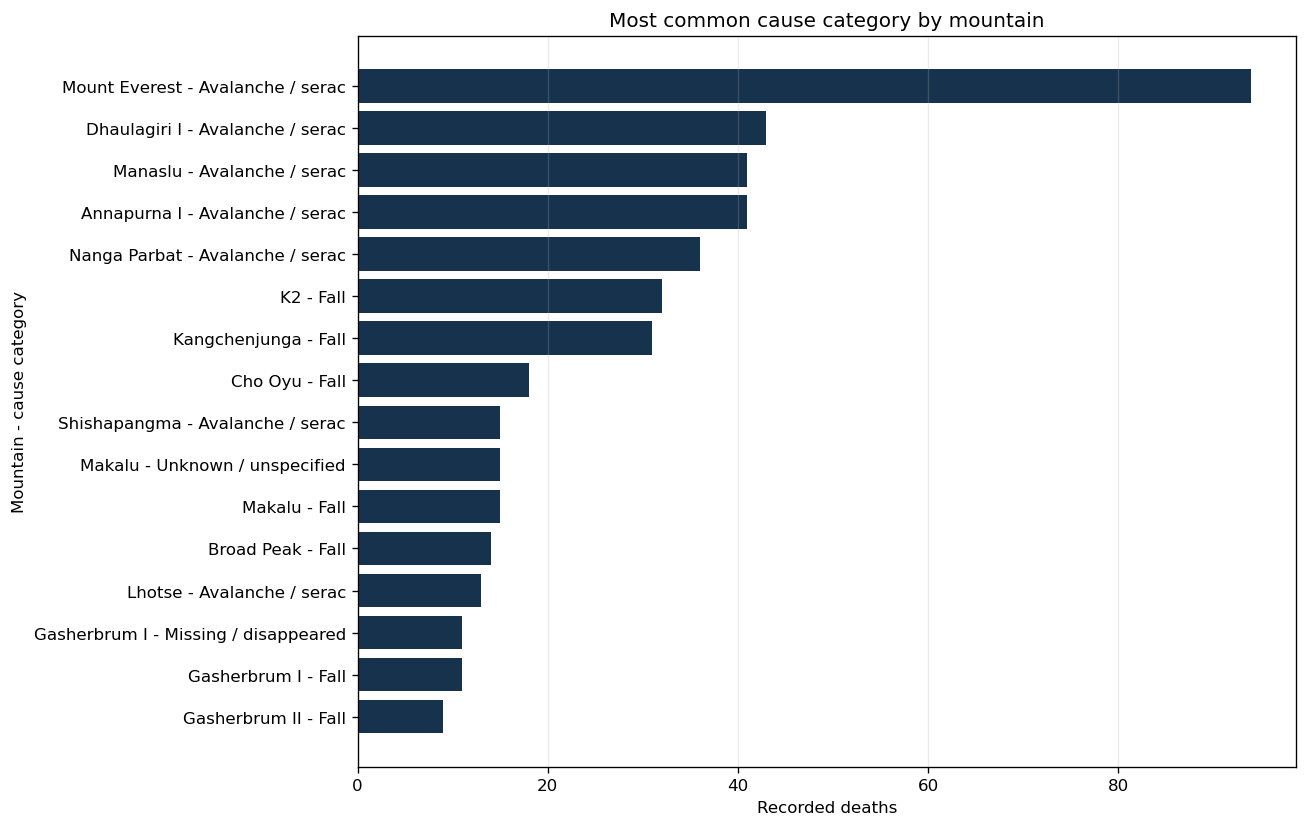

In [7]:
# Leading cause categories, including ties, for each mountain.
top = cause_counts[cause_counts['is_most_common']].sort_values(['deaths', 'Mountain'])
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top['Mountain'] + ' - ' + top['cause_category'], top['deaths'], color='#17324D')
ax.set(title='Most common cause category by mountain', xlabel='Recorded deaths', ylabel='Mountain - cause category')
ax.grid(axis='x', alpha=.25); fig.tight_layout()
fig.savefig(FIGURE_DIR / 'top_causes_by_mountain.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close(fig)

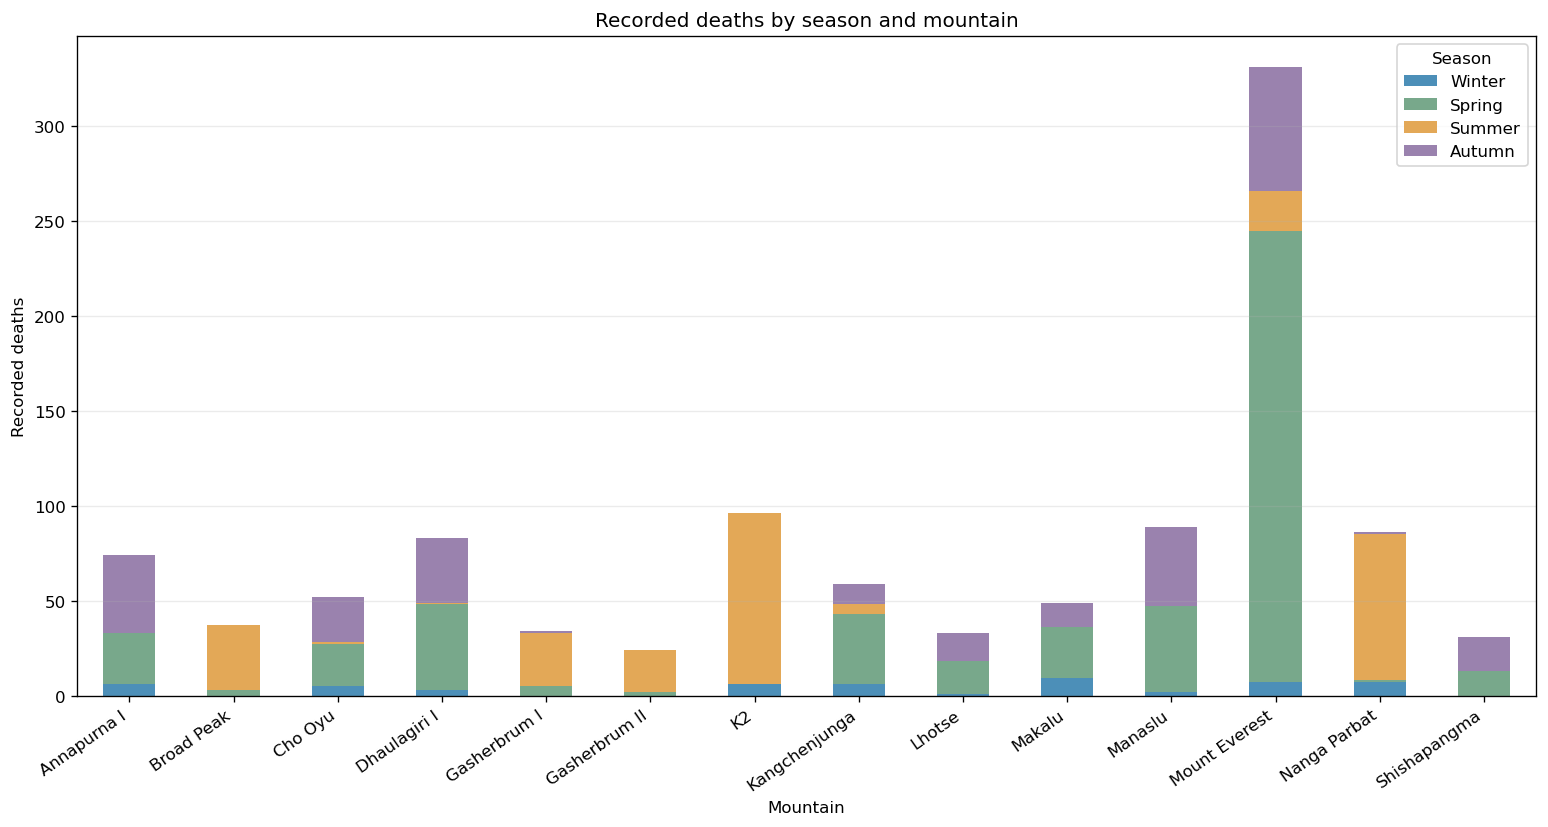

In [8]:
# Stacked seasonal counts by mountain.
season_pivot = season_counts.pivot(index='Mountain', columns='season', values='deaths')[SEASON_ORDER]
ax = season_pivot.plot(kind='bar', stacked=True, figsize=(13, 7), color=['#4C8FB8', '#78A88B', '#E3A857', '#9A82AE'])
ax.set(title='Recorded deaths by season and mountain', xlabel='Mountain', ylabel='Recorded deaths')
ax.legend(title='Season'); ax.grid(axis='y', alpha=.25)
plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig(FIGURE_DIR / 'deaths_by_season.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close()

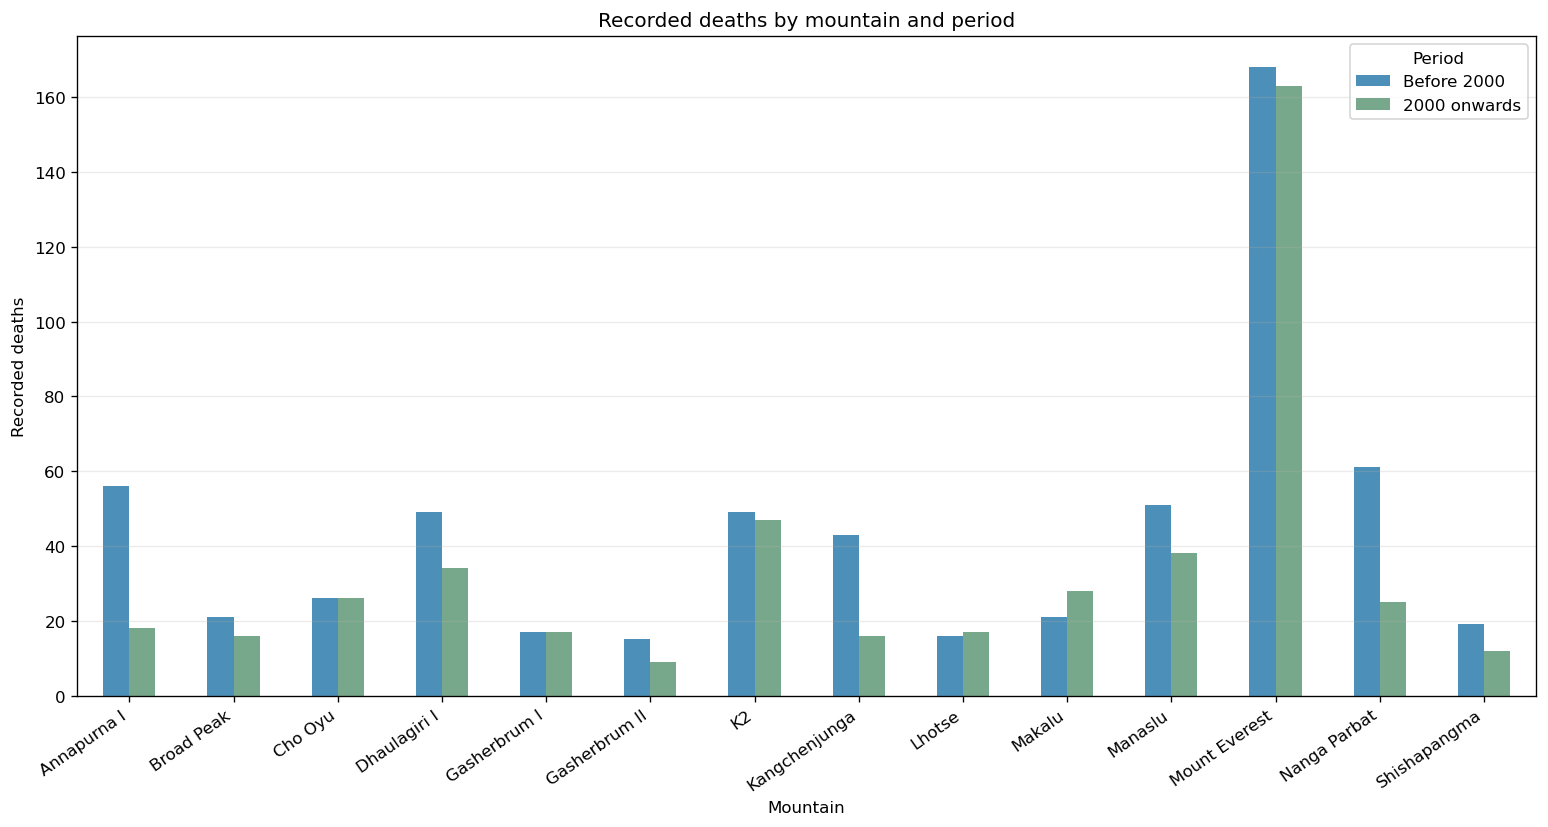

In [9]:
# Counts before 2000 and from 2000 onwards.
period_pivot = period_counts.pivot(index='Mountain', columns='period', values='deaths')[PERIOD_ORDER]
ax = period_pivot.plot(kind='bar', figsize=(13, 7), color=['#4C8FB8', '#78A88B'])
ax.set(title='Recorded deaths by mountain and period', xlabel='Mountain', ylabel='Recorded deaths')
ax.legend(['Before 2000', '2000 onwards'], title='Period'); ax.grid(axis='y', alpha=.25)
plt.xticks(rotation=35, ha='right'); plt.tight_layout()
plt.savefig(FIGURE_DIR / 'deaths_by_period.png', dpi=180, bbox_inches='tight')
plt.show(); plt.close()

## 7. Interpretation and limitations

The charts show record counts in the source CSV. Higher counts may reflect more expeditions, a longer period covered, or source completeness, rather than higher risk alone. Season is derived from the event month. Records with invalid dates remain included in cause summaries but are excluded from seasonal and period summaries. The saved CSV tables can be used for further analysis.